# Task 6 — Netflix Business Insights Report

Combine exploratory data analysis, catalogue trends, dashboards, and business recommendations into an end-to-end report.

**Project:** Auspify Technologies — Data Analysis Using Python Internship  
**Dataset:** Netflix catalogue CSV supplied for this internship  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn


### Import Libraries

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

### Load the Cleaned dataset

In [2]:
df = pd.read_csv("netflix_cleaned.csv")
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


## 2. Complete EDA and data-quality summary

In [3]:
eda = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "unique_values": df.nunique()
})
display(eda)
eda.to_csv("task6_data_quality_summary.csv")

,data_type,missing_values,unique_values
show_id,object,0,8790
type,object,0,2
title,object,0,8786
director,object,0,4528
country,object,0,86
date_added,object,0,1713
release_year,int64,0,74
rating,object,0,14
duration,object,0,220
listed_in,object,0,513


## 3. Calculate core business metrics

In [4]:
content_counts = df["type"].value_counts()
country_df = df[["show_id", "country"]].dropna().copy()
country_df = country_df[country_df["country"].ne("Unknown")]
country_df["country"] = country_df["country"].str.split(",")
country_df = country_df.explode("country")
country_df["country"] = country_df["country"].str.strip()
country_counts = country_df.groupby("country")["show_id"].nunique().sort_values(ascending=False)

year_df = df.dropna(subset=["release_year"]).copy()
year_df["release_year"] = pd.to_numeric(year_df["release_year"], errors="coerce")
year_df = year_df.dropna(subset=["release_year"])
yearly_counts = year_df.groupby("release_year")["show_id"].nunique().sort_index()

genre_df = df[["show_id", "listed_in"]].dropna().copy()
genre_df["listed_in"] = genre_df["listed_in"].str.split(",")
genre_df = genre_df.explode("listed_in")
genre_df["listed_in"] = genre_df["listed_in"].str.strip()
genre_counts = genre_df.groupby("listed_in")["show_id"].nunique().sort_values(ascending=False)

known_ratings = df.loc[df["rating"].ne("Unknown"), "rating"].value_counts()

summary = {
    "Total distinct titles": int(df["show_id"].nunique()),
    "Movies": int(df.loc[df["type"].eq("Movie"), "show_id"].nunique()),
    "TV Shows": int(df.loc[df["type"].eq("TV Show"), "show_id"].nunique()),
    "Countries represented (known)": int(country_counts.index.nunique()),
    "Genres represented": int(genre_counts.index.nunique()),
    "Known rating categories": int(known_ratings.index.nunique())
}
summary_df = pd.DataFrame(list(summary.items()), columns=["Metric", "Value"])
display(summary_df)
summary_df.to_csv("task6_summary_metrics.csv", index=False)

,Metric,Value
0,Total distinct titles,8790
1,Movies,6126
2,TV Shows,0
3,Countries represented (known),85
4,Genres represented,42
5,Known rating categories,14


## 4. Dashboard 1 — Executive KPI overview

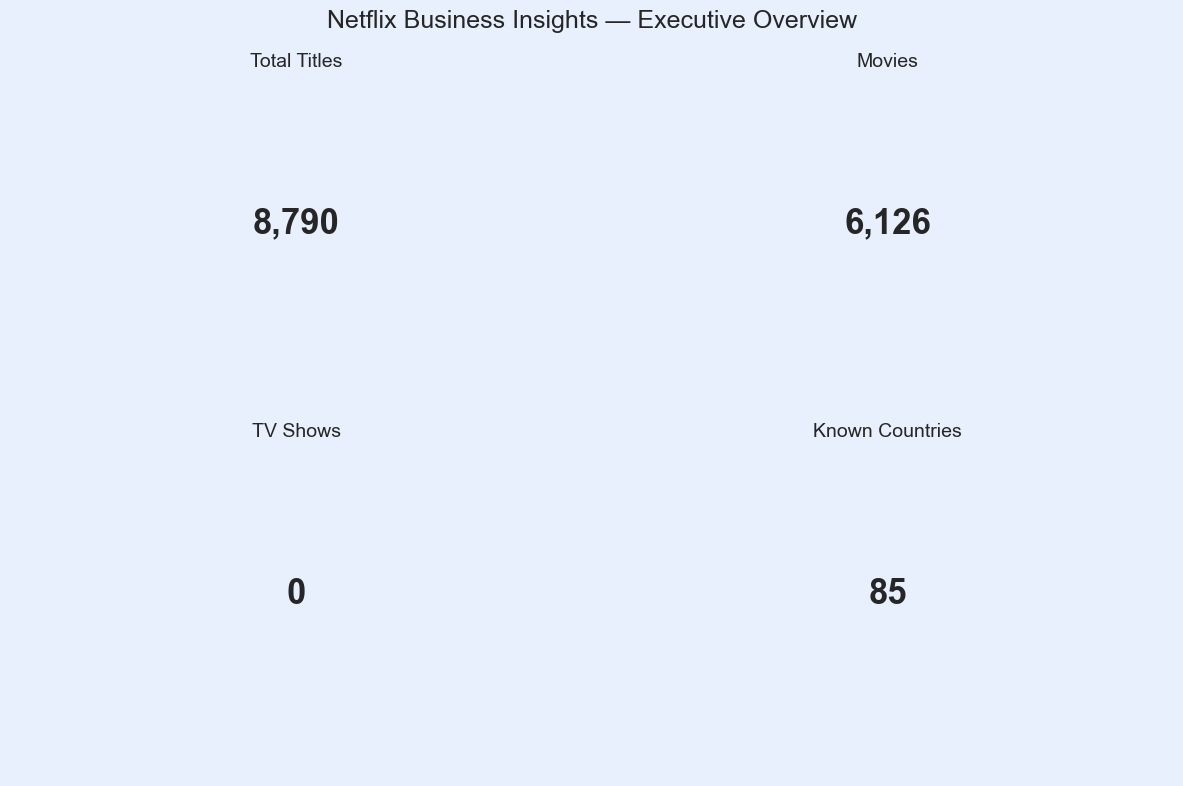

In [5]:
metrics = [
    ("Total Titles", summary["Total distinct titles"]),
    ("Movies", summary["Movies"]),
    ("TV Shows", summary["TV Shows"]),
    ("Known Countries", summary["Countries represented (known)"])
]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (label, value) in zip(axes.flat, metrics):
    ax.text(0.5, 0.55, f"{value:,}", ha="center", va="center",
            fontsize=25, fontweight="bold")
    ax.set_title(label, fontsize=14)
    ax.axis("off")
fig.patch.set_facecolor("#E8F0FE")    
fig.suptitle("Netflix Business Insights — Executive Overview", fontsize=18)
plt.tight_layout()
plt.savefig("task6_executive_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Dashboard 2 — Content, countries, and genres

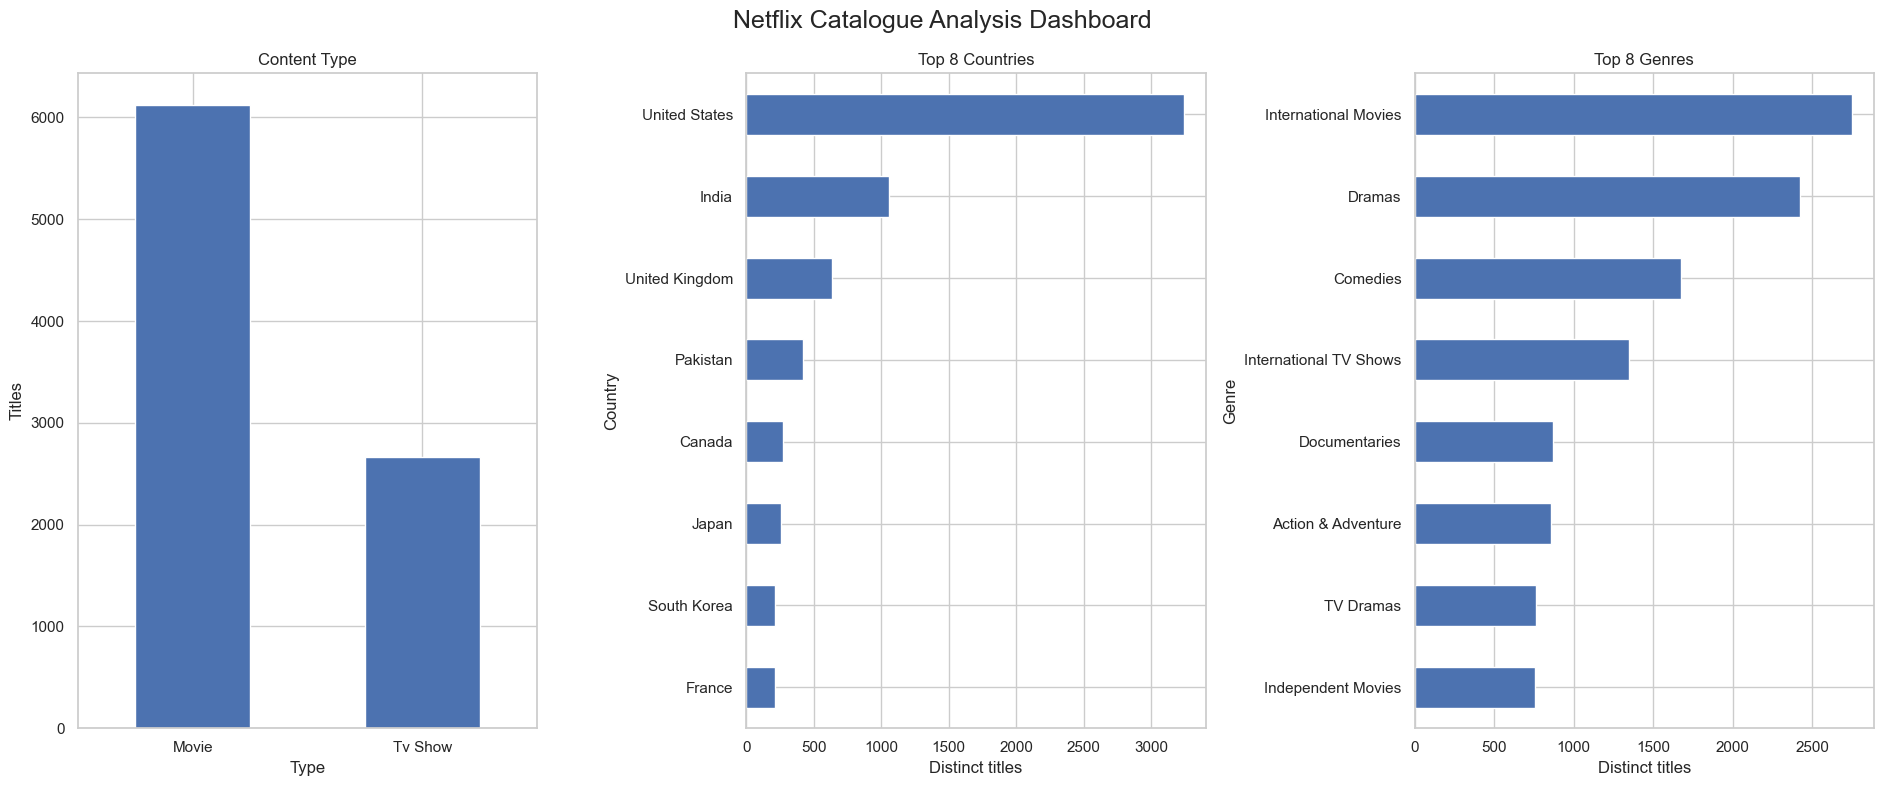

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(19, 8))
content_counts.plot(kind="bar", ax=axes[0])
axes[0].set(title="Content Type", xlabel="Type", ylabel="Titles")
axes[0].tick_params(axis="x", rotation=0)

country_counts.head(8).sort_values().plot(kind="barh", ax=axes[1])
axes[1].set(title="Top 8 Countries", xlabel="Distinct titles", ylabel="Country")

genre_counts.head(8).sort_values().plot(kind="barh", ax=axes[2])
axes[2].set(title="Top 8 Genres", xlabel="Distinct titles", ylabel="Genre")

fig.suptitle("Netflix Catalogue Analysis Dashboard", fontsize=18)
plt.tight_layout()
plt.savefig("task6_content_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Dashboard 3 — Release years and ratings

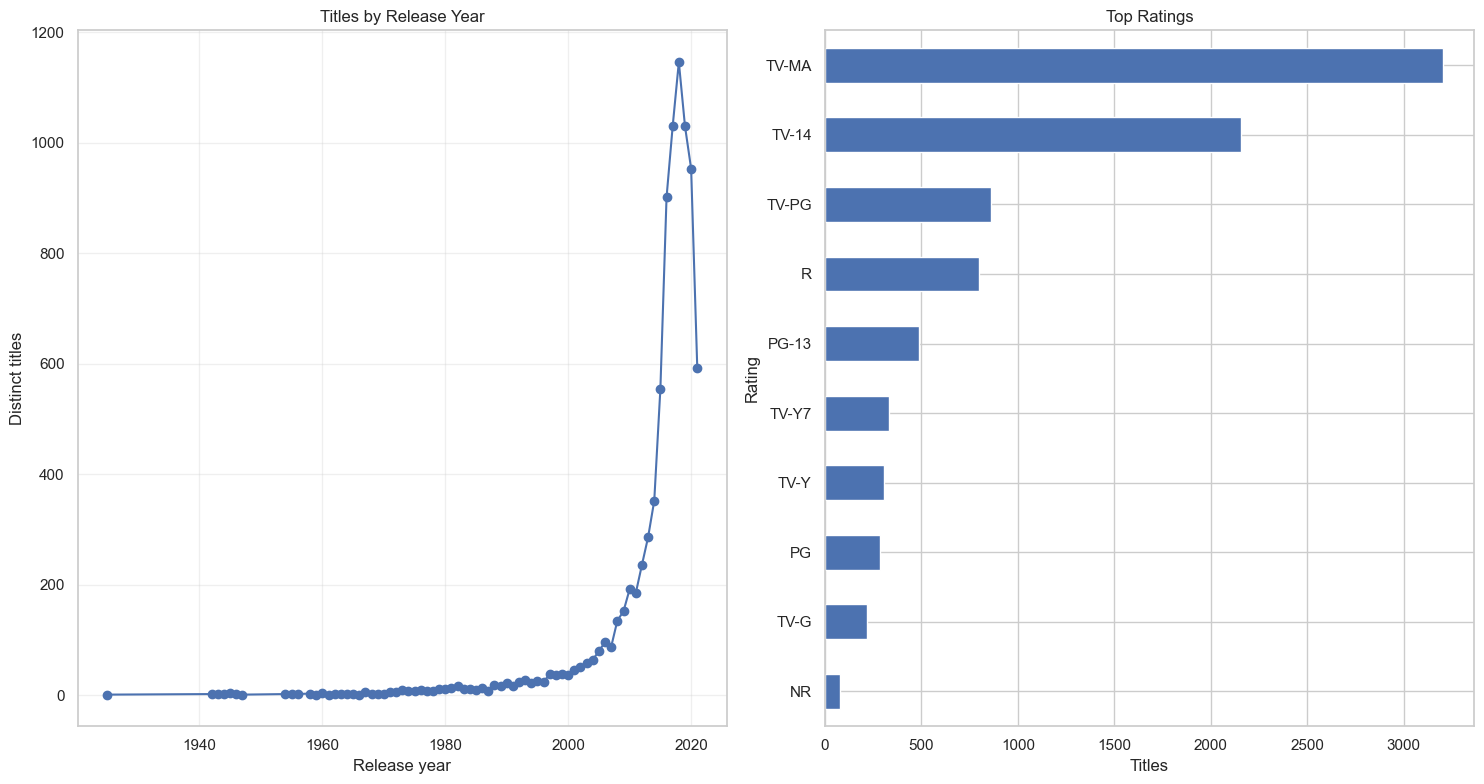

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8))
axes[0].plot(yearly_counts.index, yearly_counts.values, marker="o")
axes[0].set(title="Titles by Release Year", xlabel="Release year", ylabel="Distinct titles")
axes[0].grid(True, alpha=0.3)

rating_counts = df["rating"].fillna("Unknown").value_counts().drop(labels=["Unknown"], errors="ignore")
rating_counts.head(10).sort_values().plot(kind="barh", ax=axes[1])
axes[1].set(title="Top Ratings", xlabel="Titles", ylabel="Rating")

plt.tight_layout()
plt.savefig("task6_trends_ratings_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Generate a data-driven findings table

In [8]:
findings = [
    ("Content type with most titles",
     content_counts.index[0] if not content_counts.empty else "N/A"),
    ("Country with most associated titles",
     country_counts.index[0] if not country_counts.empty else "N/A"),
    ("Most common genre",
     genre_counts.index[0] if not genre_counts.empty else "N/A"),
    ("Release year with most titles",
     int(yearly_counts.idxmax()) if not yearly_counts.empty else "N/A"),
    ("Most common known rating",
     known_ratings.index[0] if not known_ratings.empty else "N/A")
]
findings_df = pd.DataFrame(findings, columns=["Analysis", "Result"])
display(findings_df)
findings_df.to_csv("task6_key_findings.csv", index=False)

,Analysis,Result
0,Content type with most titles,Movie
1,Country with most associated titles,United States
2,Most common genre,International Movies
3,Release year with most titles,2018
4,Most common known rating,TV-MA


## 9. Final deliverables
This notebook exports three dashboard images, a data-quality summary, KPI metrics, and a key-findings table into `outputs/`. Use these images and tables in a PDF report with sections for executive summary, dataset overview, cleaning, Tasks 2–5 analysis, insights, limitations, and conclusion.